# Laplace-preconditioned MCMC exploration

Visual walk-through of the MALA sampler of `bayes_cep.mcmc` preconditioned by the Laplace approximation of `bayes_cep.laplace` for the single retained patient (`example_data/raw/`, `example_data/preprocessing/`, `example_data/map/`). The approximation $\mathcal N(m_\mathrm{MAP}, \Gamma)$, $\Gamma = \Gamma_0 - V D V^T$, enters the `ls_bayesian` MCMC model as its `approximation` (through `LowRankGaussianMeasure`):

- **`PMALA`**: MALA preconditioned by $\Gamma$, i.e. the Langevin drift $-\frac{2\delta}{2+\delta}\,\Gamma\,(\nabla\Phi + \Gamma_0^{-1}u)$ and noise $\mathcal N(0, \Gamma)$ (the state-independent case of the infinite-dimensional manifold MALA). For $\Gamma = \Gamma_0$ it is the plain MALA. It assumes a centred prior, which holds here.

If the posterior were Gaussian with covariance $\Gamma$, it would accept every proposal for $\delta$ near $1$. It is far from Gaussian in the 15820 dimensions, so the step widths that work are small. `pixi run example-mcmc-laplace` runs a preconditioned sampler non-interactively (`single_runs.mcmc_laplace.PreconditionedMcmcRun`); studies `mcmc_laplace` and `mcmc_baseline` sweep step widths.

This notebook is for interactive/visual inspection only. Every chain step needs a forward and an adjoint solve, so the chain is short; `RUN_SAMPLER = False` reads the stored chain instead.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pyvista as pv
import zarr
from ls_bayesian.common.logging import BaseLogger, LoggerSettings
from ls_bayesian.lowrank.eigensolvers import RandomizedDoublePassSolver
from ls_bayesian.mcmc.sampler import SamplerSettings

from bayes_cep.laplace.builder import LaplaceBuilder, LaplaceSettings
from bayes_cep.mcmc.builder import (
    SAMPLE_STORE_NAME,
    MCMCAlgorithmName,
    MCMCBuilder,
    MCMCSettings,
    ZarrStorageSettings,
)
from bayes_cep.mcmc.measures import LowRankGaussianMeasure
from bayes_cep.mesh.interpolation import NearestNeighborInterpolationStrategy
from bayes_cep.mesh.io import load_pyvista_mesh
from bayes_cep.posterior.builder import PosteriorBuilder, PosteriorSettings
from bayes_cep.posterior.likelihood import LikelihoodSettings
from bayes_cep.statistics.axial_diagnostics import (
    compute_axial_autocorrelation,
    compute_axial_effective_sample_size,
)
from bayes_cep.statistics.axial_statistics import (
    compute_axial_mean_and_variance,
    compute_standard_deviation_degrees,
)
from single_runs.data import PreprocessedData
from single_runs.reference import reference_eikonal_settings, reference_prior_parameters

pv.set_jupyter_backend("trame")

DATA_DIR = Path.cwd().parent / "example_data"
RAW_DIR = DATA_DIR / "raw"
PREPROCESSING_DIR = DATA_DIR / "preprocessing"
MAP_DIR = DATA_DIR / "map"
CHAIN_DIR = DATA_DIR / "mcmc_laplace_notebook"

## Load preprocessed data and the MAP estimate

In [2]:
mesh = load_pyvista_mesh(RAW_DIR / "mesh.vtu")
basis_vectors = np.load(RAW_DIR / "basis_vecs.npy")
data = PreprocessedData.load(PREPROCESSING_DIR)
map_estimate = np.load(MAP_DIR / "map_estimate.npy")

print(f"{mesh.n_points} vertices, {mesh.n_cells} triangles")
print(f"{data.observed_vertex_indices.shape[0]} observed vertices")

15820 vertices, 31375 triangles
1000 observed vertices


## Build the posterior and the Laplace approximation

`PosteriorBuilder.build_components` returns the likelihood, forward map and prior; `PosteriorComponents.to_log_posterior` composes the same objects into the `LogPosterior` the samplers use. The misfit Hessian has at most one nonzero eigenvalue per observation, so the rank is at most the number of observations (1000). `NUM_EIGENVALUES = 500` is a compromise: the directions beyond the smallest kept eigenvalue keep their wide prior variance, so check the printed value (a rank near 1000 resolves the spectrum, at about a minute of eigensolve) when the preconditioned sampler rejects.

In [4]:
posterior_settings = PosteriorSettings(
    mesh=mesh,
    basis_vectors=basis_vectors,
    prior_mean_vector=data.prior_mean,
    prior_parameters=reference_prior_parameters(),
    eikonal_settings=reference_eikonal_settings(),
    likelihood_settings=LikelihoodSettings(
        num_vertices=mesh.n_points,
        observed_vertex_indices=data.observed_vertex_indices,
        data_vector=data.observed_activation_times,
        noise_variance=data.noise_variance,
    ),
)
components = PosteriorBuilder(
    posterior_settings, interpolation_strategy=NearestNeighborInterpolationStrategy()
).build_components()
log_posterior = components.to_log_posterior()

NUM_EIGENVALUES = 800
laplace_settings = LaplaceSettings(
    eigensolver=RandomizedDoublePassSolver(oversampling=20, seed=0),
    num_eigenvalues=NUM_EIGENVALUES,
    minimum_eigenvalue=1e-6,
    sample_seed=0,
)
approximation = LaplaceBuilder(laplace_settings, components).build(map_estimate)
eigenvalues = approximation.eigenpairs.eigenvalues
laplace_measure = LowRankGaussianMeasure(approximation.gaussian)

print(f"kept {eigenvalues.size} of {NUM_EIGENVALUES} eigenpairs")
print(f"eigenvalues from {eigenvalues[0]:.3e} down to {eigenvalues[-1]:.3e}")

kept 774 of 800 eigenpairs
eigenvalues from 1.088e+06 down to 1.446e-02


## Build the sampler

`MCMCSettings.algorithm = PMALA` selects the preconditioned MALA; `MCMCBuilder` takes the Laplace measure as `approximation` (and refuses a missing one). The step width $0.05$ is the reference value. The chain writes a Zarr store to `CHAIN_DIR`.

In [7]:
STEP_WIDTH = 0.01
CHAIN_DIR.mkdir(parents=True, exist_ok=True)
mcmc_builder = MCMCBuilder(
    MCMCSettings(
        algorithm=MCMCAlgorithmName.PMALA,
        step_width=STEP_WIDTH,
        storage=ZarrStorageSettings(chunk_size=100),
    ),
    log_posterior,
    output_dir=CHAIN_DIR,
    approximation=laplace_measure,
)

## Run the chain

> **Note:** every step needs a forward eikonal solve on the full mesh and an adjoint solve, roughly one to two seconds per step, so long chains take a long time. To only inspect the results of an earlier run, set `RUN_SAMPLER = False`: it skips the sampling and reads the existing Zarr store (it is only created, and overwritten, when the sampler is built, i.e. when `RUN_SAMPLER` is `True`). The chain starts at the MAP estimate.

In [8]:
RUN_SAMPLER = True
NUM_SAMPLES = 1000
SEED = 0

if RUN_SAMPLER:
    with BaseLogger(LoggerSettings(), prefix="pmala") as logger:
        sampler = mcmc_builder.build(logger=logger)
        sampler.run(
            initial_state=map_estimate,
            settings=SamplerSettings(num_samples=NUM_SAMPLES, log_interval=1),
            seed=SEED,
        )
    print(f"final acceptance rate {float(mcmc_builder.outputs[0].all_values[-1]):.3f}")

[PCN_PRECONDITIONED] model.approximation given: proposing from it, correcting relative to model.reference.
[PCN_PRECONDITIONED]  Iteration     Time [s] mean of acceptance mean         mean of mean
[PCN_PRECONDITIONED] --------------------------------------------------------------------
[PCN_PRECONDITIONED]          0        0.027 +1.000e+00         -1.117e-01   -1.117e-01  
[PCN_PRECONDITIONED]          1        1.743 +1.000e+00         -1.108e-01   -1.112e-01  
[PCN_PRECONDITIONED]          2        2.620 +1.000e+00         -1.111e-01   -1.112e-01  
[PCN_PRECONDITIONED]          3        3.485 +1.000e+00         -1.103e-01   -1.110e-01  
[PCN_PRECONDITIONED]          4        4.375 +1.000e+00         -1.106e-01   -1.109e-01  
[PCN_PRECONDITIONED]          5        5.244 +1.000e+00         -1.105e-01   -1.108e-01  
[PCN_PRECONDITIONED]          6        6.158 +8.571e-01         -1.105e-01   -1.108e-01  
[PCN_PRECONDITIONED]          7        7.062 +7.500e-01         -1.105e-01   -1.107

## Chain diagnostics

The minimum split-chain effective sample size over a random subset of vertices (all 15820 are possible but slow for a notebook), after the burn-in. A chain that does not move has an acceptance rate of about $1/N$ (the initial state counts as accepted) and no defined effective sample size.

In [9]:
BURN_IN = 100
MAX_LAG = 100
NUM_VERTICES_FOR_ESS = 200

chain = zarr.open_group(CHAIN_DIR / SAMPLE_STORE_NAME, mode="r")["data"]
vertex_subset = np.sort(
    np.random.default_rng(1).choice(mesh.n_points, NUM_VERTICES_FOR_ESS, replace=False)
)
subset = np.asarray(chain.get_orthogonal_selection((slice(None), vertex_subset)))
effective_sample_size = compute_axial_effective_sample_size(subset, MAX_LAG, BURN_IN)
print(
    f"minimum effective sample size: {np.nanmin(effective_sample_size.effective_sample_size):.1f}"
)

minimum effective sample size: 4.7


## Traces

The angle at a few vertices along the chain. A trace that is flat has not moved from the MAP estimate.

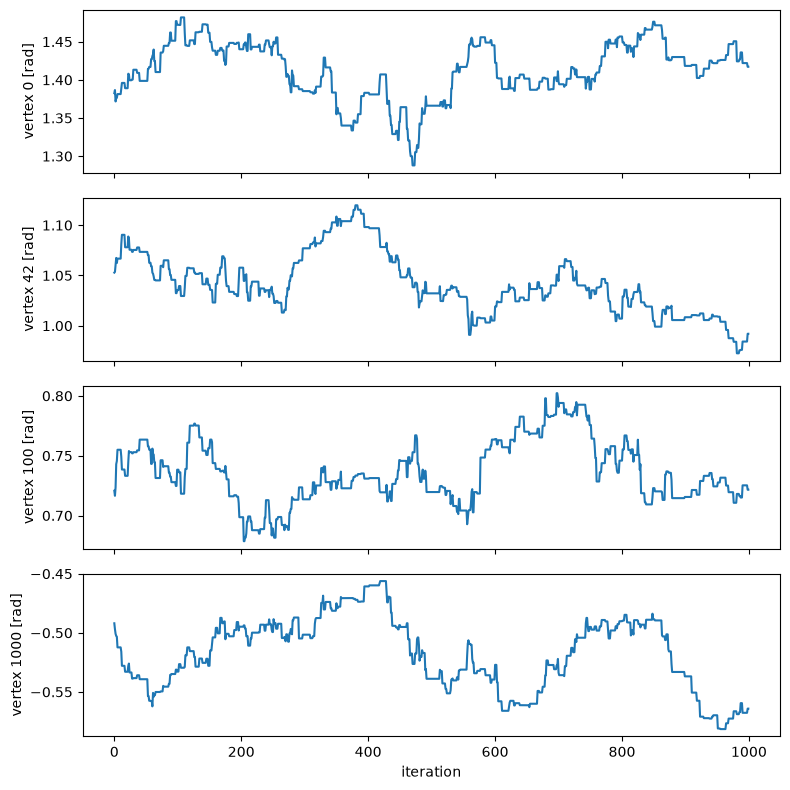

In [ ]:
TRACED_VERTICES = (0, 42, 100, 1000, 5000)

fig, axes = plt.subplots(
    len(TRACED_VERTICES), 1, figsize=(8, 2 * len(TRACED_VERTICES)), sharex=True
)
for axis, vertex in zip(axes, TRACED_VERTICES, strict=True):
    axis.plot(np.asarray(chain[:, vertex]))
    axis.set_ylabel(f"vertex {vertex} [rad]")
axes[-1].set_xlabel("iteration")
fig.tight_layout()

## Autocorrelation

The axial autocorrelation function of the same vertices after the burn-in, against the lag (`compute_axial_autocorrelation`, on $\sin(2(\theta - \mu))$). A function that decays slowly means strongly correlated samples and a small effective sample size; the lags are limited by `MAX_LAG`.

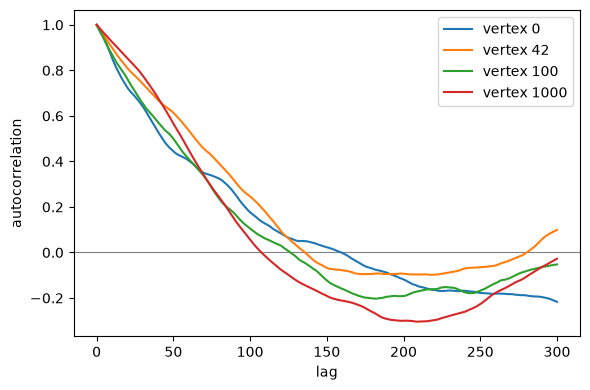

In [13]:
traces = np.asarray(chain.get_orthogonal_selection((slice(None), list(TRACED_VERTICES))))
autocorrelation = compute_axial_autocorrelation(traces, 300, BURN_IN)

fig, axis = plt.subplots(figsize=(6, 4))
axis.axhline(0.0, color="gray", linewidth=0.8)
for vertex, function in zip(TRACED_VERTICES, autocorrelation.T, strict=True):
    axis.plot(function, label=f"vertex {vertex}")
axis.set_xlabel("lag")
axis.set_ylabel("autocorrelation")
axis.legend()
fig.tight_layout()

## Posterior mean and standard deviation

The axial mean and variance of the chain after the burn-in (`compute_axial_mean_and_variance`): the fiber angle is $\pi$-periodic, so the mean is the direction of the mean resultant vector of the doubled angles, and the variance is $-\tfrac{1}{2}\ln R$ with $R$ its length. Both are fields on the mesh, with one value per vertex; the variance is shown as a standard deviation in degrees.

In [19]:
chain_mean, chain_variance = compute_axial_mean_and_variance(chain, burn_in=BURN_IN)

### Posterior mean [rad]

The mean angle on a cyclic color range, as in `map.ipynb` and `mcmc.ipynb`. The colors are interpolated, not the angles (`interpolate_before_map=False`): the axial mean jumps between $-\pi/2$ and $\pi/2$ for the same fiber direction, and interpolating the angle would sweep the whole colormap across such a triangle.

In [32]:
plot_mesh = mesh.copy()
plot_mesh.point_data["mean angle [rad]"] = chain_mean
plotter = pv.Plotter()
plotter.add_mesh(plot_mesh, scalars="mean angle [rad]", cmap="hsv", clim=(-np.pi / 2, np.pi / 2), interpolate_before_map=False)
plotter.add_text("posterior axial mean")
plotter.show()

Widget(value='<iframe src="http://localhost:43651/index.html?ui=P_0x7fe8c23647d0_3&reconnect=auto" class="pyvi…

### Posterior standard deviation [deg]

The square root of the axial variance $-\tfrac{1}{2}\ln R$, converted to degrees (`compute_standard_deviation_degrees`).

In [33]:
plot_mesh = mesh.copy()
plot_mesh.point_data["axial std [deg]"] = compute_standard_deviation_degrees(chain_variance)
plotter = pv.Plotter()
plotter.add_mesh(plot_mesh, scalars="axial std [deg]", cmap="viridis")
plotter.add_text("posterior axial standard deviation [deg]")
plotter.show()

Widget(value='<iframe src="http://localhost:43651/index.html?ui=P_0x7fe8c231aad0_4&reconnect=auto" class="pyvi…